# Иерархический кластерный анализ

## Цель работы

Выявить структуру сходства между отсканированными изображениями цифр на основе семи бинарных признаков с помощью иерархического кластерного анализа. Определить оптимальное количество кластеров и провести содержательную интерпретацию полученных групп.

## Загрузка и предобработка данных

In [ ]:
import pandas as pd
import numpy as np
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, MultipleLocator
import math
import seaborn as sns
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)
from sklearn.feature_selection import mutual_info_classif

In [ ]:
df = pd.read_csv("digit.dat", sep=";")

In [ ]:
# посмотрим на несколько первых записей
df.head()

,A,B,C,D,E,F,G,H,A2,B2,C2,D2,E2,F2,G2,H2
0,seven,ONE,ZERO,ONE,ZERO,ZERO,ONE,ZERO,seven,ONE,ZERO,ONE,ZERO,ZERO,ONE,ZERO
1,one,ZERO,ZERO,ONE,ZERO,ZERO,ONE,ZERO,one,ZERO,ZERO,ONE,ZERO,ZERO,ONE,ZERO
2,four,ZERO,ONE,ONE,ONE,ZERO,ONE,ZERO,four,ZERO,ONE,ONE,ONE,ZERO,ONE,ZERO
3,two,ONE,ONE,ONE,ONE,ONE,ZERO,ZERO,two,ONE,ONE,ONE,ONE,ONE,ZERO,ZERO
4,eight,ZERO,ONE,ONE,ONE,ONE,ONE,ONE,eight,ZERO,ONE,ONE,ONE,ONE,ONE,ONE


Видим, что все столбцы признаков повторяются в данных по два раза. Проверим, действительно ли они идентичны.

In [ ]:
pairs = [('A','A2'), ('B','B2'), ('C','C2'), ('D','D2'),
         ('E','E2'), ('F','F2'), ('G','G2'), ('H','H2')]

for c1, c2 in pairs:
    a = df[c1].str.strip()
    b = df[c2].str.strip()

    equal = a.equals(b)
    print(f'{c1} vs {c2}: identical = {equal}')

A vs A2: identical = True
B vs B2: identical = True
C vs C2: identical = True
D vs D2: identical = True
E vs E2: identical = True
F vs F2: identical = True
G vs G2: identical = True
H vs H2: identical = True


Теперь удалим эти столбцы, так как они не несут никакой новой информации

In [ ]:
df = df.drop(columns=['A2', 'B2', 'C2', 'D2', 'E2', 'F2', 'G2', 'H2'])

Разделим столбцы на признаки и target (переменную в которой лежит сама цифра)

In [ ]:
target = 'A'

X = df.drop(columns=[target])
y = df[target]

In [ ]:
# интересно, что ONE написано везде с лишним пробелом
# unique() вывел бы пропуски, если бы они имелись - видим, что пропусков нет
for col in X.columns:
  print(f'{col}: {X[col].unique()}')

# лишние пробелы есть и в значениях target
print(f'\nA: {y.unique()}')

B: ['ONE ' 'ZERO']
C: ['ZERO' 'ONE ']
D: ['ONE ' 'ZERO']
E: ['ZERO' 'ONE ']
F: ['ZERO' 'ONE ']
G: ['ONE ' 'ZERO']
H: ['ZERO' 'ONE ']

A: ['seven' 'one  ' 'four ' 'two  ' 'eight' 'five ' 'six  ' 'zero ' 'nine '
 'three']


In [ ]:
X = X.replace({'ONE ': 1, 'ZERO': 0}).infer_objects(copy=False)
y = y.str.strip()

data = pd.concat([y, X], axis=1)
data.head()

/tmp/ipykernel_2146/3989026699.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X = X.replace({'ONE ': 1, 'ZERO': 0}).infer_objects(copy=False)


,A,B,C,D,E,F,G,H
0,seven,1,0,1,0,0,1,0
1,one,0,0,1,0,0,1,0
2,four,0,1,1,1,0,1,0
3,two,1,1,1,1,1,0,0
4,eight,0,1,1,1,1,1,1


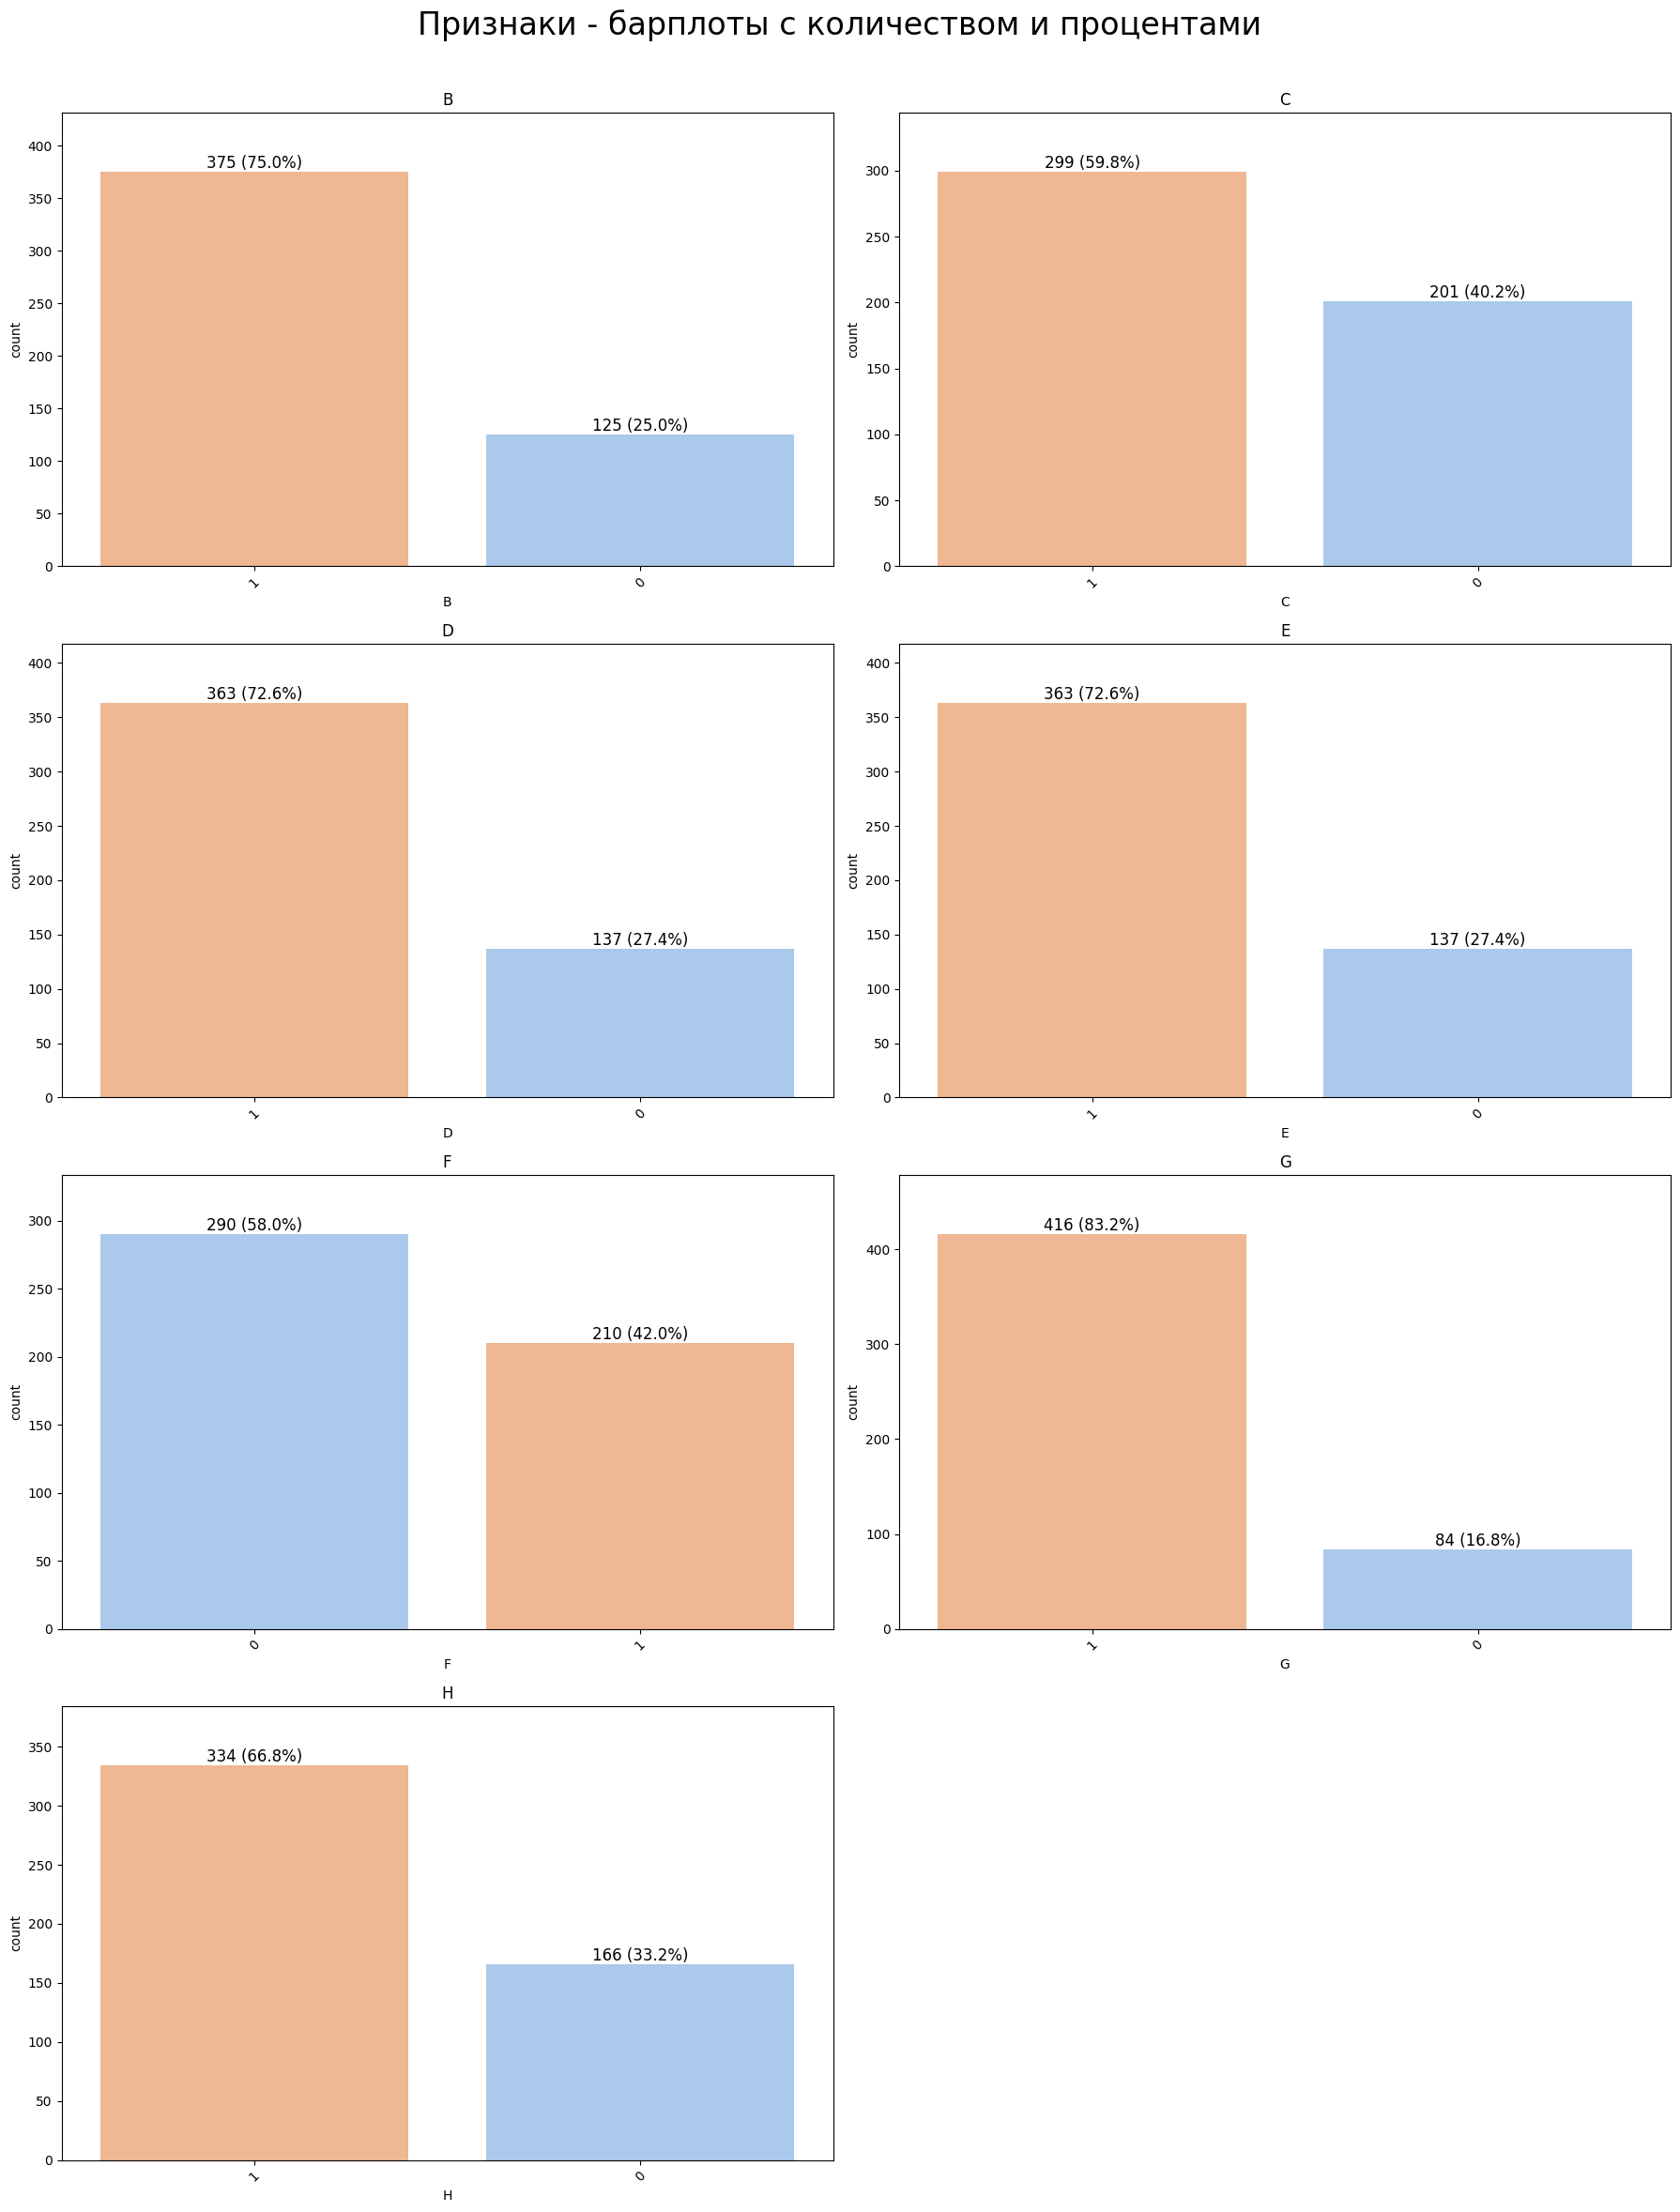

In [ ]:
columns = X.columns

n_cat = len(columns)
cols = 2
rows = math.ceil(n_cat / cols)

fig_cat, axes_cat = plt.subplots(rows, cols, figsize=(cols * 9, rows * 6))
axes_cat = axes_cat.flatten()

for i, col in enumerate(columns):
    ax = axes_cat[i]
    order = X[col].value_counts().index
    counts = X[col].value_counts()
    total = len(X)

    sns.countplot(data=X, x=col, hue=col, ax=ax, order=order, palette="pastel", legend=False)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)

    for p in ax.patches:
        count = int(p.get_height())
        percent = 100 * count / total
        ax.annotate(
            f"{count} ({percent:.1f}%)",
            (p.get_x() + p.get_width() / 2.0, p.get_height()),
            ha="center",
            va="bottom",
            fontsize=12,
        )
    ax.set_ylim(0, max(counts.values) * 1.15)

# Удаляем лишние оси
for j in range(i + 1, len(axes_cat)):
    fig_cat.delaxes(axes_cat[j])

fig_cat.suptitle("Признаки - барплоты с количеством и процентами", fontsize=24)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

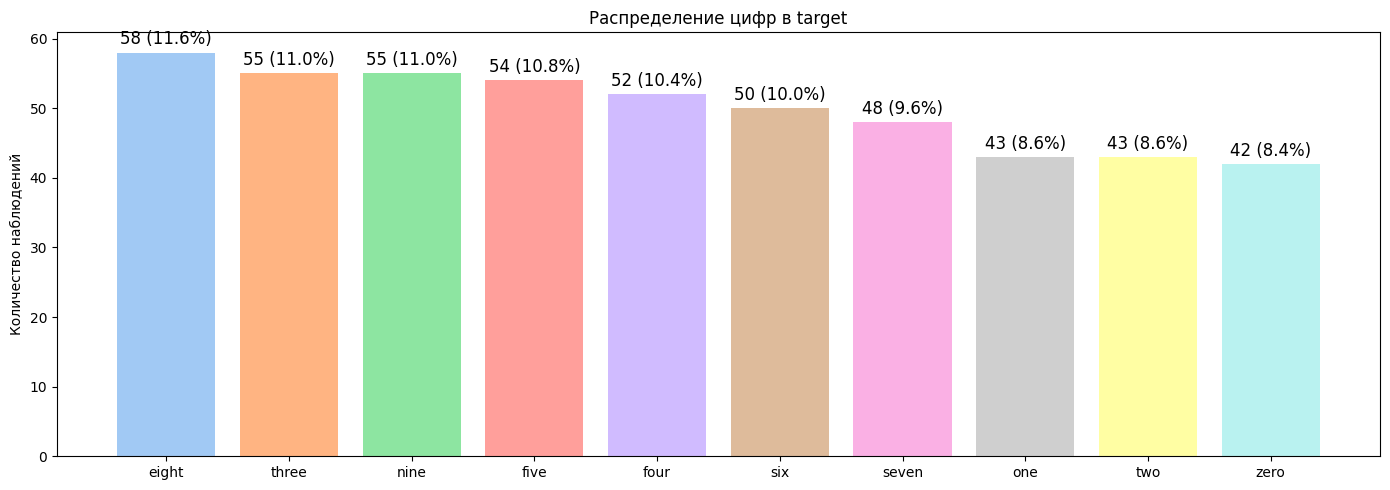

In [ ]:
counts = y.value_counts()
pct = y.value_counts(normalize=True) * 100

order = counts.sort_values(ascending=False).index
counts = counts.loc[order]
pct = pct.loc[order]

fig, ax = plt.subplots(figsize=(14, 5))
colors = sns.color_palette("pastel", n_colors=len(counts))

bars = ax.bar(counts.index.astype(str), counts.values, color=colors)

ax.set_title('Распределение цифр в target')
ax.set_ylabel('Количество наблюдений')

ax.bar_label(
    bars,
    labels=[f'{c} ({p:.1f}%)' for c, p in zip(counts.values, pct.values)],
    padding=3, fontsize=12,
)

plt.tight_layout()
plt.show()

In [ ]:
def draw_digit_on_ax(
    row_index: int,
    ax: plt.Axes,
    X: pd.DataFrame = X,
    y: pd.DataFrame = y
) -> None:
    """
    Рисует одну цифру на заданной оси по переданному индексу строки

    Параметры:
    row_index : int
        Номер строки в X и y
    ax : matplotlib.axes.Axes
        Ось, на которой выполняется отрисовка
    X : pd.DataFrame
        DataFrame с колонками B–H
    y : pd.DataFrame
        DataFrame с колонкой A
    """
    if row_index >= len(df):
        print(f"Ошибка: индекс {row_index} выходит за пределы DataFrame")
        return

    row = X.iloc[row_index].copy()
    ax.set_xlim(-0.1, 1.1)
    ax.set_ylim(-0.1, 1.1)
    ax.axis('off')
    ax.set_title(f'Объект {row_index}, цифра {y.iloc[row_index]}', fontsize=14)

    segments = [
        (row['B'], [0.25, 0.75], [1.0, 1.0]),
        (row['C'], [0.25, 0.25], [0.5, 1.0]),
        (row['D'], [0.75, 0.75], [0.5, 1.0]),
        (row['E'], [0.25, 0.75], [0.5, 0.5]),
        (row['F'], [0.25, 0.25], [0.0, 0.5]),
        (row['G'], [0.75, 0.75], [0.0, 0.5]),
        (row['H'], [0.25, 0.75], [0.0, 0.0]),
    ]

    for on, xs, ys in segments:
        ax.plot(xs, ys, color='black' if on == 1 else 'white')

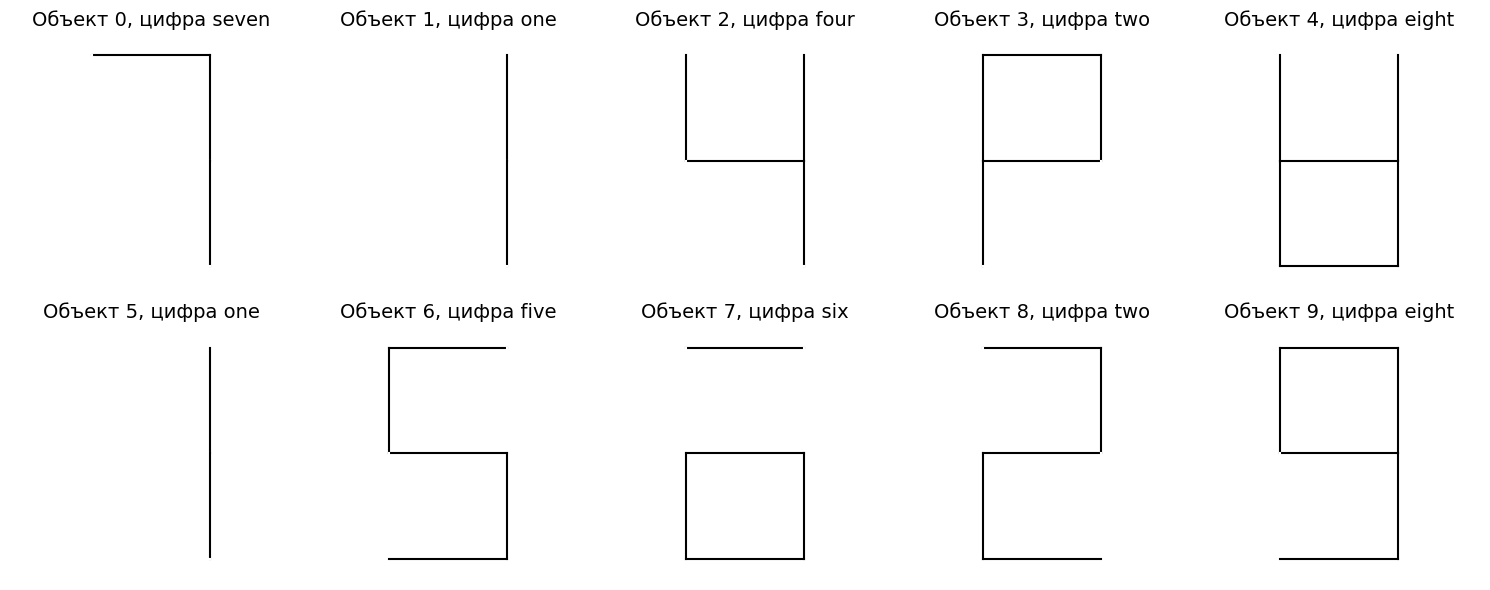

In [ ]:
n = 10
cols = 5
rows = math.ceil(n / cols)

fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 3))
axes = axes.flatten()

for i in range(n):
    draw_digit_on_ax(i, axes[i])

plt.tight_layout()
plt.show()

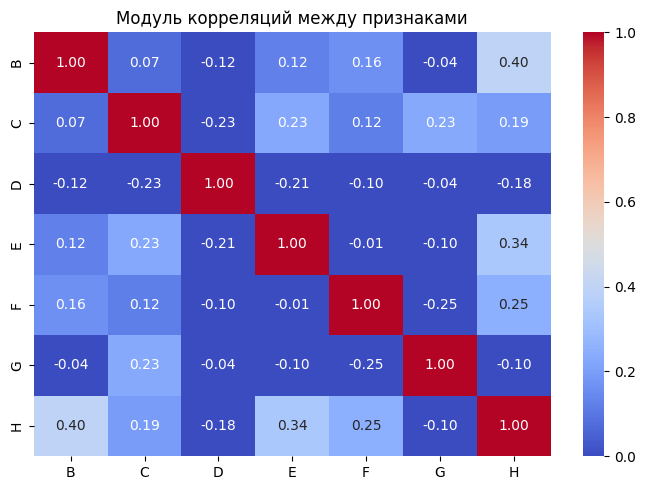

In [ ]:
corr_matrix = X.corr()

plt.figure(figsize=(7, 5))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=0, vmax=1,
    square=False,
    fmt='.2f'
)

plt.title("Модуль корреляций между признаками")
plt.tight_layout()
plt.show()

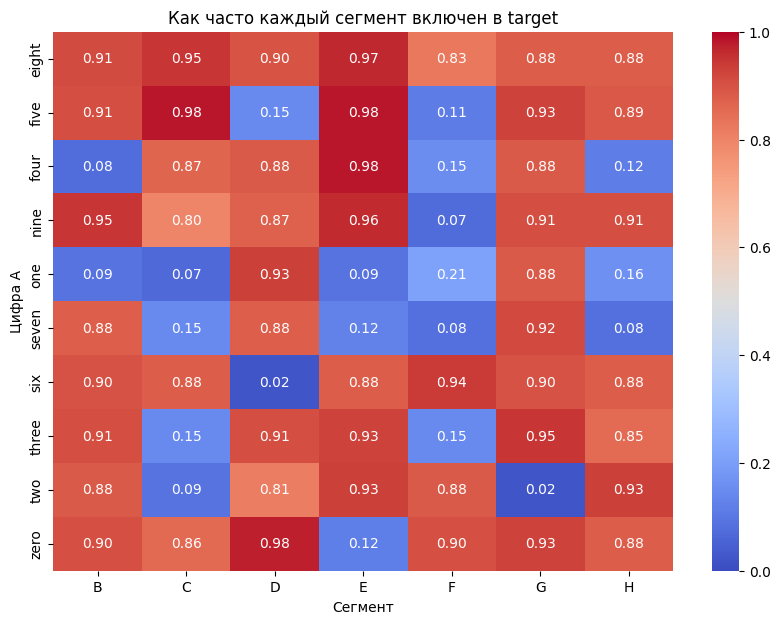

In [ ]:
segments = X.columns

profiles = data.groupby('A')[segments].apply(
    lambda x: (x == 1).mean()
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    profiles,
    annot=True,
    cmap='coolwarm',
    vmin=0,
    vmax=1,
    fmt='.2f'
)

plt.xlabel('Сегмент')
plt.ylabel('Цифра A')
plt.title('Как часто каждый сегмент включен в target')
plt.show()

Проведенный разведочный анализ показал, что данные хорошо структурированы и вполне пригодны для иерархической кластеризации, но имеют ряд особенностей, которые необходимо учитывать при выборе метрик.

Распределение признаков (B–H) показывают умеренную или высокую долю единиц. Особенно выделяется сегмент G (нижний правый вертикальный): он равен 1 в 83% наблюдений. Его дисперсия минимальна, поэтому вклад в различение объектов будет небольшим. Остальные сегменты более информативны.

Распределение цифр (переменная A) достаточно сбалансировано: частоты лежат в узком диапазоне от 8,4 % (zero) до 11,6 % (eight). Сильного перекоса нет, поэтому размеры кластеров в дальнейшем не будут сильно искажены частотой отдельных цифр. Это упрощает интерпретацию — если какой-то кластер окажется заметно больше остальных, это скорее отразит реальную схожесть паттернов, а не артефакт несбалансированности.

Графику, показывающий то, как часто сегменты входят в ту или иную цифру из target, доказывает, что в данных есть неправильно отсканированные цифры.

Матрица корреляций (модули) показывает, что сегменты в целом слабо связаны друг с другом. Самые заметные связи — B–H (0,40) и E–H (0,34), остальные значительно ниже. Сильной мультиколлинеарности нет. В связи с этим можно использовать обычные бинарные меры расстояния, не опасаясь сильного искажения из-за зависимых признаков. В то же время наличие даже умеренных корреляций делает чисто евклидово расстояние менее предпочтительным — оно будет частично дублировать информацию.

## Выбор метрик

Для того чтобы начать иерархический кластерный анализ, необходимо выбрать
- метрику, по которой будем измерять расстояние между точками
- метрику, по которой будем измерять расстояние между кластерами

Расстояние между точками: Hamming

Для бинарных векторов (как здесь):  
$$
d_H(\mathbf{x}, \mathbf{y}) = \sum_{i=1}^p I(x_i \neq y_i)
$$

где $I$ — индикатор. Максимум — 7 для наших данных. Прямо считает количество линий, которых нет в одной цифре.

В данных переменные измерены строго в номинальной шкале с значениями 0 и 1 (линия есть/отсутствует). Это классические бинарные признаки без ранга, без пропорциональности и без естественной числовой величины. Hamming — идеально ложится под эти данные: она напрямую считает количество отличающихся позиций (т.е. сколько линий отсутствуют в одной цифре по сравнению с другой), не вводя искусственные веса или преобразования.

Расстояние между кластерами: Average

Объединяет два кластера на основе среднего попарного расстояния между всеми объектами внутри них:  
$$
d_{\text{avg}}(C_i, C_j) = \frac{1}{|C_i| \cdot |C_j|} \sum_{x \in C_i} \sum_{y \in C_j} d(x, y)
$$

Простой, устойчивый метод, не смещает кластеры в одну сторону.

## Построение дендрограммы

Для удобного автоматизированного построения дендограммы я использовала функции `linkage()` и `dendrogram()`.

Функция `linkage()` принимает на вход матрицу данных и автоматически строит последовательность объединений объектов в кластеры.  

Синтаксис:  
```python
Z = linkage(y, metric='...', method='...')
```
где  
- `y` — это исходные данные  
- `metric` — способ расчета расстояния между объектами (`'hamming'` в нашем случае)
- `method` — способ расчета расстояния между кластерами (`'average'` в нашем случае);  
- остальные параметры — вспомогательные.  

`linkage()` возвращает матрицу связей Z размера `(n-1, 4)`:  
- столбец 0 и 1 — индексы двух кластеров, которые объединились,  
- столбец 2 — расстояние, на котором произошло объединение,  
- столбец 3 — размер нового кластера.  

Эта матрица содержит всю информацию о порядке объединений на всех шагах итеративного процесса.

Функция `dendrogram()` — это визуализатор результатов `linkage()`. Она берет матрицу Z и рисует древовидную структуру.

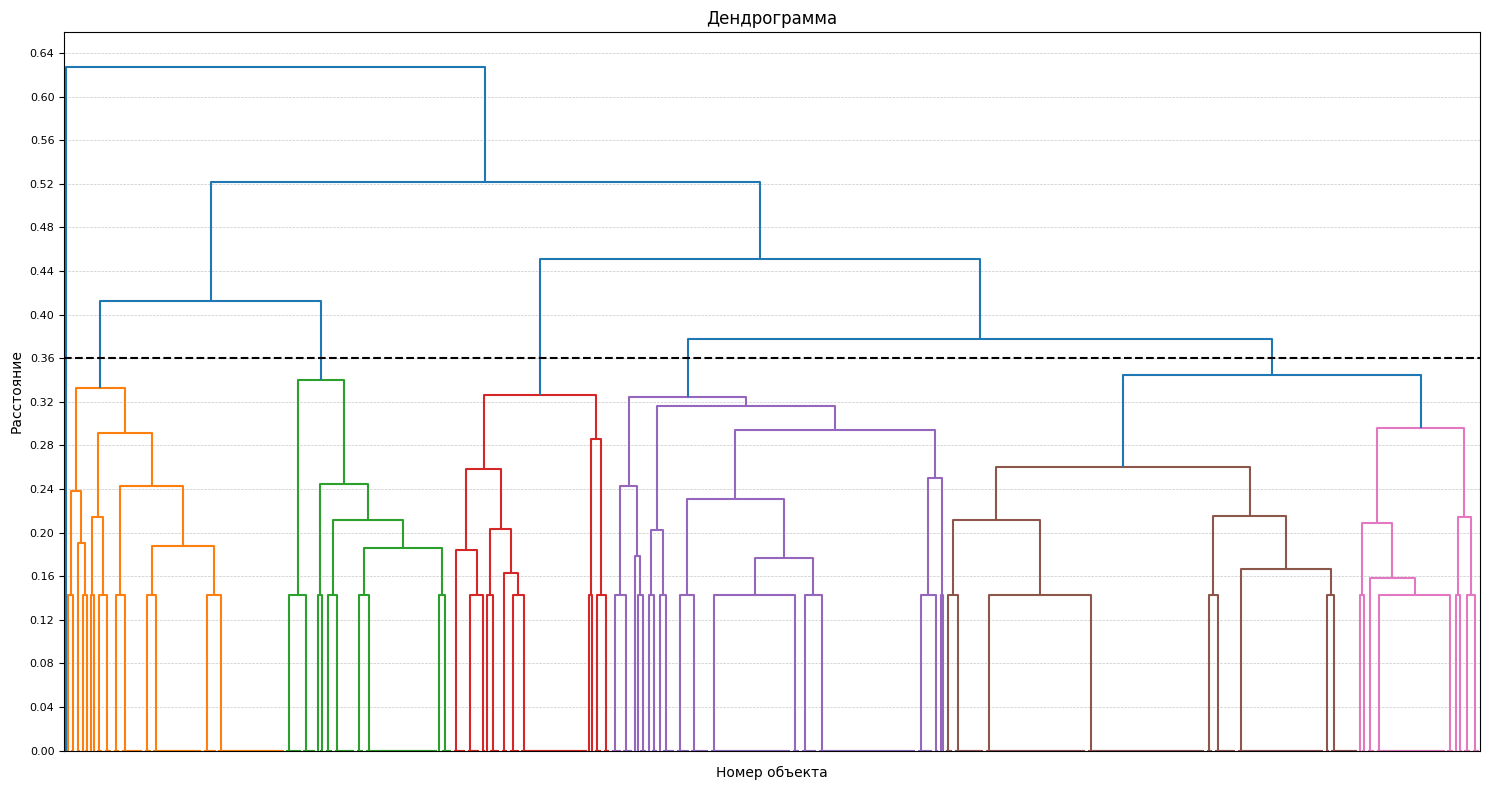

In [ ]:
n = len(X)

distance_metric = 'hamming'
linkage_method = 'average'

Z = linkage(X, metric=distance_metric, method=linkage_method)

fig, ax = plt.subplots(figsize=(15, 8))
dendrogram(Z, color_threshold=0.344, leaf_font_size=2, ax=ax)
ax.set_xticklabels([])
ax.yaxis.set_major_locator(MaxNLocator(nbins=20))
ax.tick_params(axis='y', labelsize=8)
ax.grid(axis='y', which='major', linestyle='--', linewidth=0.5, alpha=0.7)
ax.set_axisbelow(True)
ax.axhline(y=0.36, color='black', linestyle='--', linewidth=1.5)

ax.set_title('Дендрограмма')
ax.set_xlabel('Номер объекта')
ax.set_ylabel('Расстояние')
plt.tight_layout()
plt.show()

Визуально я считаю, что остановиться нужно на уровне примерно 0.36.

Следующий уровень - 0.40, на нем уже есть длинные горизонтальные линии (в оранжевых и красных кластерах). Это значит, что на одной высоте много объектов объединились на примерно одинаковом расстоянии (почти одновременно) - они образуют один большой, рыхлый кластер. Вероятно, эти объекты не очень похожи.

Также видно, что в самом начале есть один изолированный объект, который объединился в кластер с другими только на самом последнем этапе. Это явный выброс, скорее всего связанный с тем, что отсканирован с ошибкой.

## Уточнение числа кластеров (график каменистой осыпи)

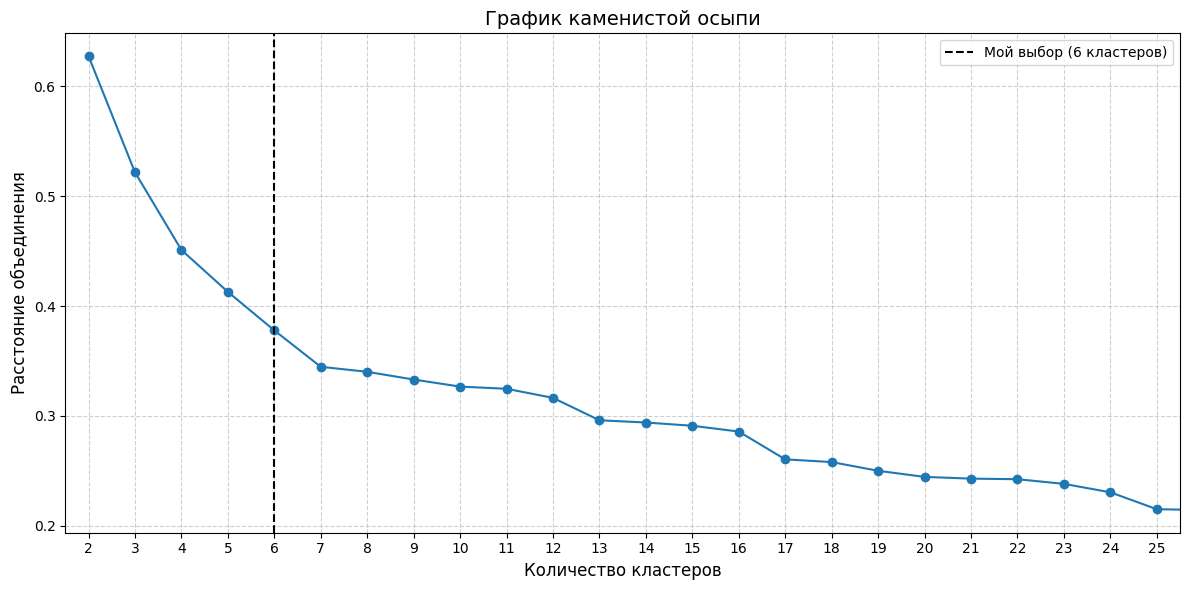

In [ ]:
n_last = 25
distances = Z[-n_last:, 2]
n_clusters = np.arange(2, n_last + 2)

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(n_clusters, distances[::-1], 'o-', markersize=6, linewidth=1.5)

ax.set_xlabel('Количество кластеров', fontsize=12)
ax.set_ylabel('Расстояние объединения', fontsize=12)
ax.set_title('График каменистой осыпи', fontsize=14)

ax.xaxis.set_major_locator(MultipleLocator(1))
ax.set_xlim(1.5, n_last + 0.5)

ax.grid(True, linestyle='--', alpha=0.6)
ax.axvline(x=6, color='black', linestyle='--', linewidth=1.5, label='Мой выбор (6 кластеров)')
ax.legend()

plt.tight_layout()
plt.show()

## Результаты кластеризации

Для разрезания уже построенной дендрограммы на конечное число кластеров использовалась функция `fcluster()`  

Синтаксис:  
```python
labels = fcluster(Z, t=<some_number>, criterion='distance')
```  
где  
- `Z` — матрица связей, возвращённая `linkage()`
- `t` — порог (в нашем случае 2.0)
- `criterion` — критерий разрезания

`fcluster()` возвращает одномерный массив `labels` длиной n=500, где для каждого объекта записан номер кластера (от 1 до k)

In [ ]:
labels_ham = fcluster(Z, 0.344, criterion='distance')
print(f"Количество кластеров при пороге 0.344: {len(set(labels_ham))}")

Количество кластеров при пороге 0.344: 7


In [ ]:
ct = pd.crosstab(
    labels_ham,
    y,
    rownames=['Кластер'],
    colnames=['Цифра'],
    margins=True,
    margins_name='Всего',
)

print(ct)

Цифра    eight  five  four  nine  one  seven  six  three  two  zero  Всего
Кластер                                                                   
1            0     0     4     0   33     37    0      1    0     2     77
2            4     0    37     3    9      1    0      4    0     1     59
3            4     1     3     4    0      1    0      2   40     1     56
4            6    45     4     7    0      1   49      3    2     1    118
5           42     7     4    39    0      5    1     41    0     7    146
6            2     1     0     2    0      3    0      4    1    30     43
7            0     0     0     0    1      0    0      0    0     0      1
Всего       58    54    52    55   43     48   50     55   43    42    500


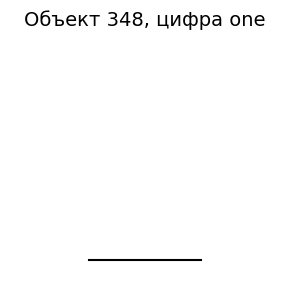

In [ ]:
outlier_indice = np.where(labels_ham == 7)[0][0]

fig, ax = plt.subplots(figsize=(3, 3))
draw_digit_on_ax(outlier_indice, ax)
plt.tight_layout()
plt.show()

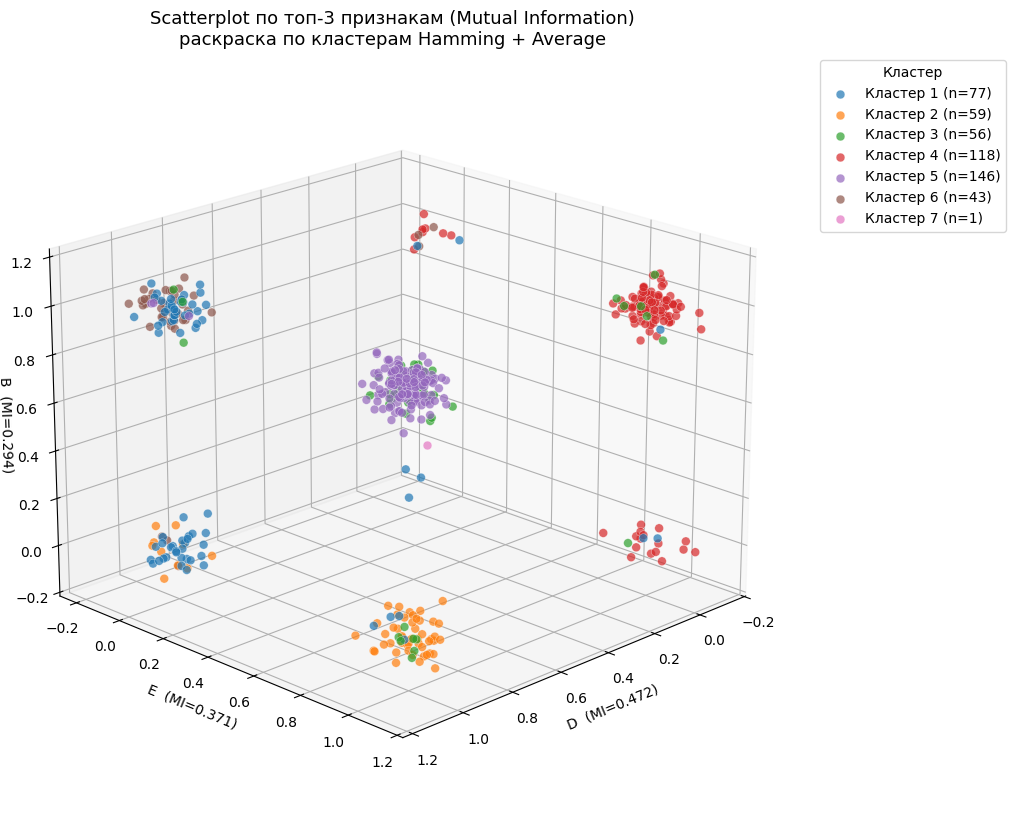

In [32]:
mi = mutual_info_classif(X, labels_ham, discrete_features=True)
mi_series = pd.Series(mi, index=X.columns).sort_values(ascending=False)
top3 = mi_series.head(3).index.tolist()

rng = np.random.default_rng(42)
jitter = 0.05

df_plot = pd.DataFrame({
    top3[0]: X[top3[0]].astype(float).values + rng.normal(0, jitter, len(X)),
    top3[1]: X[top3[1]].astype(float).values + rng.normal(0, jitter, len(X)),
    top3[2]: X[top3[2]].astype(float).values + rng.normal(0, jitter, len(X)),
    'cluster': np.asarray(labels_ham).astype(str),
})

fig = plt.figure(figsize=(14, 9))
ax = fig.add_subplot(111, projection='3d')

palette = sns.color_palette('tab10', n_colors=df_plot['cluster'].nunique())

for (name, group), color in zip(df_plot.groupby('cluster'), palette):
    ax.scatter(
        group[top3[0]], group[top3[1]], group[top3[2]],
        s=40, alpha=0.7, color=color,
        label=f'Кластер {name} (n={len(group)})',
        edgecolors='white', linewidths=0.3,
    )

ax.set_title('Scatterplot по топ-3 признакам (Mutual Information)\nраскраска по кластерам Hamming + Average',
             fontsize=13)
ax.set_xlabel(f'{top3[0]}  (MI={mi_series[top3[0]]:.3f})')
ax.set_ylabel(f'{top3[1]}  (MI={mi_series[top3[1]]:.3f})')
ax.set_zlabel(f'{top3[2]}  (MI={mi_series[top3[2]]:.3f})', labelpad=-1)
ax.legend(title='Кластер', loc='upper left', bbox_to_anchor=(1.05, 1))
ax.view_init(elev=20, azim=45)

fig.subplots_adjust(left=0.05, right=0.85, top=0.90, bottom=0.05)
plt.show()

## Оценка качества кластеризации

1. Silhouette Score

Показывает насколько хорошо каждый объект вписывается в свой кластер и насколько далеко он находится от соседних кластеров.

Для каждого объекта рассчитываются:

- $a(i)$ — среднее расстояние от объекта до остальных объектов своего кластера
- $b(i)$ — минимальное среднее расстояние от объекта до объектов другого кластера

Формула:

$$s(i)=\frac{b(i)-a(i)}{\max(a(i),b(i))}$$

Итоговый Silhouette Score — среднее значение по всем объектам

2. ARI (Adjusted Rand Index)

Показывает насколько полученное разбиение на кластеры соответствует исходным классам

Метрика сравнивает все возможные пары объектов и проверяет:

- находятся ли два объекта в одном кластере и принадлежат ли одному исходному классу
- находятся ли они в разных кластерах и принадлежат ли разным исходным классам

Затем рассчитывается скорректированное совпадение с учетом случайного разбиения

Чем выше ARI, тем лучше соответствие кластеров исходным меткам.

3. NMI (Normalized Mutual Information)

Показывает насколько информация о принадлежности объекта к кластеру помогает определить его исходную цифру A

Метрика основана на взаимной информации (Mutual Information), которая измеряет, насколько знание одной переменной уменьшает неопределенность относительно другой

Чем выше NMI, тем лучше соответствие между кластеризацией и исходными классами

In [ ]:
def evaluate_clustering(X: pd.DataFrame,
                        labels: np.ndarray,
                        y_true: pd.DataFrame,
                        metric_for_silhouette: str,
                        name: str) -> pd.Series:
    """
    Считает набор метрик качества кластеризации и возвращает их одной строкой.

    Параметры:
    X: pd.DataFrame
        DataFrame с колонками B–H
    labels: np.ndarray
        Метки кластера
    y_true:pd.DataFrame
        DataFrame с колонкой A
    metric_for_silhouette: str
        Метрика, используемая для расчета silhouette
    name: str, default="Clustering"
        Имя строки результата — попадет в Series.name

    Возвращает
    pd.Series
        pd.Series со значениями метрик
    """

    results = {}

    results['Silhouette'] = silhouette_score(X, labels, metric=metric_for_silhouette)
    results['ARI'] = adjusted_rand_score(y_true, labels)
    results['NMI'] = normalized_mutual_info_score(y_true, labels)

    return pd.Series(results, name=name)

res_ham = evaluate_clustering(
    X, labels_ham, y_true=y,
    metric_for_silhouette='hamming',
    name='Hamming + Average'
)

res_ham

,Hamming + Average
Silhouette,0.373704
ARI,0.337239
NMI,0.485042


## Выводы

Результаты кластеризации позволили выделить семь групп одна из которых содержит только единственный выброс. Видно, что цифры действительно группируются по визуальному сходству. Например, в первом кластере преобладают цифры 1 и 7, во втором — цифра 4, в третьем — цифра 2, в четвертом — цифры 5 и 6, пятый кластер объединяет цифры 3, 8, 9, шестой - 0. Все группы имеют определенные общие визуальные характеристики.

Качество кластеризации (метрики):
- Silhouette = 0.37 — умеренное качество разделения (кластеры частично перекрываются).
- ARI = 0.34 и NMI = 0.49 — кластеры лишь частично соответствуют исходным цифрам, что ожидаемо из-за сильных искажений при сканировании и ограниченности семи бинарных признаков.

Scatterplot по трём наиболее информативным сегментам (D, E, B, отобранным по Mutual Information) наглядно показывает, что кластеры занимают разные комбинации включённых сегментов. При этом часть групп хорошо отделяется, а некоторые (особенно крупные) имеют внутреннюю неоднородность.